# Ethanol — argon contamination at 270 eV

FLASH2, beamtime 11024642. Compare the integrated electron and ion spectra of ethanol delay scans with different levels of argon contamination.

Run from the repository root or `analysis/notebooks` with the FLASH Remote kernel. Uses config 1 `time_resolved` aggregates (GMD × delay × TOF), reading only first moments. No third-harmonic runs or pure argon reference are included.

The working model is that the spectra are a linear mixture of ethanol and argon, and that the ion gates near m/q = 31 and 20 track their respective yields. These are **provisional markers**, not pure species selections. The saved ion spectra show broad and overlapping features; needle motion may also affect the mass calibration and detection efficiency. The aim is to test the model before applying any correction to time-resolved data.

1. Load data and calibrated axes
2. Integrated electron and ion spectra; inspect mass gates
3. Ion yields and argon-to-ethanol ratio
4. Electron spectra normalised to mass 31
5. Pairwise differences
6. Linear regression and reconstructed spectra
7. Model checks and limitations

## 1. Load data

In [1]:
import sys
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

# Works from analysis/notebooks or the repository root.
repo = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'analysis/scripts/config.py').is_file()), None)
if repo is None:
    raise FileNotFoundError('Run from the repository root or analysis/notebooks')
scripts = str(repo / 'analysis/scripts')
if scripts not in sys.path:
    sys.path.insert(0, scripts)

from config import COMBINED_DIR
import calibration

In [2]:
# ---- Select groups of delay scans -------------------------------------------

GROUPS = {
    # '270 eV short 4': sorted(COMBINED_DIR.glob(
    #     'run60587_Ethanol_delay_scan_short_4_270eV_2808844787_aggregates_tr.h5')),

    '270 eV short 5': sorted(COMBINED_DIR.glob(
        'run60587_Ethanol_delay_scan_short_5_270eV_2808857928_aggregates_tr.h5')),

    '270 eV short 6': sorted(COMBINED_DIR.glob(
        'Ethanol_delay_scan_short_6_270eV_2808874942_aggregates_tr.h5')),

    # '270 eV short 7': sorted(COMBINED_DIR.glob(
    #     'Ethanol_delay_scan_short_7_270eV_2808887431_aggregates_tr.h5')),

    '270 eV short 8': sorted(COMBINED_DIR.glob(
        'run60588_Ethanol_delay_scan_short_8_270eV_2808927435_aggregates_tr.h5')),

    '270 eV r3': sorted(COMBINED_DIR.glob(
        '*Ethanol_delay_scan_r_3_270eV_2809043098_aggregates_tr.h5')),

    '270 eV reduced P': sorted(COMBINED_DIR.glob(
        '*Ethanol_delay_scan_reduced_p_270eV_2809083145_aggregates_tr.h5')),

}

GMD_BINS = None              # None: all; otherwise list of GMD bin indices
NORMALISE = 'per_uJ'         # 'per_uJ' or 'per_shot'

FS_PER_STAGE_UNIT = 0.349 / 1000
Z_ZERO = 0
DELAY_SIGN = 1

# Use the same delay interval for all groups by default.
# Set to None to use the full scans, except for the reduced-pressure cut below.
COMMON_DELAY_RANGE = (-3, 15)
DELAY_RANGES = {
    '270 eV reduced P': (-3, 16),
}

for name, files in GROUPS.items():
    print(f'\n{name}: {len(files)} files')
    for path in files:
        print(' ', path.name)


270 eV short 5: 1 files
  run60587_Ethanol_delay_scan_short_5_270eV_2808857928_aggregates_tr.h5

270 eV short 6: 1 files
  Ethanol_delay_scan_short_6_270eV_2808874942_aggregates_tr.h5

270 eV short 8: 1 files
  run60588_Ethanol_delay_scan_short_8_270eV_2808927435_aggregates_tr.h5

270 eV r3: 1 files
  Ethanol_delay_scan_r_3_270eV_2809043098_aggregates_tr.h5

270 eV reduced P: 1 files
  Ethanol_delay_scan_reduced_p_270eV_2809083145_aggregates_tr.h5


In [3]:
# Read only the first moments and TOF bin edges.
# D, C and G are means per shot, in GMD x delay bins.

groups = {}
for name, files in GROUPS.items():
    if not files:
        print(f'\n{name}: no files, skipping')
        continue

    combined = {}
    axes = {}
    print(f'\n{name}')

    for path in files:
        with h5py.File(path, 'r') as f:
            if f.attrs['config'] != 1 or f.attrs['mode'] != 'time_resolved':
                raise ValueError(f'{path.name}: expected config 1 time_resolved aggregates')

            edges = {key: f[key][:] for key in ('tof_edges', 'ion_tof_edges')}
            if not axes:
                axes = edges
            elif any(not np.array_equal(edges[key], axes[key]) for key in axes):
                raise ValueError(f'{path.name}: different TOF edges within group {name}')

            n = f['n_per_bin'][:]
            D, C, G = f['D'][:], f['C'][:], f['G'][:]
            z_edges = f['z_edges'][:]
            gmd_edges = f['gmd_edges'][:]

        if n.ndim != 2 or G.shape != n.shape or D.shape != (*n.shape, len(edges['tof_edges']) - 1) or C.shape != (*n.shape, len(edges['ion_tof_edges']) - 1) or len(z_edges) != n.shape[1] + 1:
            raise ValueError(f'{path.name}: unexpected aggregate shapes')
        if len(gmd_edges) != n.shape[0] + 1:
            raise ValueError(f'{path.name}: unexpected GMD edges')
        print('  GMD edges (uJ):', np.round(gmd_edges, 3))
        bins = slice(None) if GMD_BINS is None else GMD_BINS
        n, D, C, G = n[bins], D[bins], C[bins], G[bins]
        # Select the delay range for each group.
        delay_edges = DELAY_SIGN * (z_edges - Z_ZERO) * FS_PER_STAGE_UNIT
        delay = (delay_edges[:-1] + delay_edges[1:]) / 2

        lo, hi = DELAY_RANGES.get(name, (-np.inf, np.inf))
        if COMMON_DELAY_RANGE is not None:
            lo = max(lo, COMMON_DELAY_RANGE[0])
            hi = min(hi, COMMON_DELAY_RANGE[1])
        keep = (delay >= lo) & (delay <= hi)
        if not keep.any() or n[:, keep].sum() <= 0:
            raise ValueError(f'{path.name}: no shots in selected GMD/delay range')

        n_before = n.sum()

        n = n[:, keep]
        D = D[:, keep]
        C = C[:, keep]
        G = G[:, keep]

        print(f'  Delay range: {delay[keep].min():.2f} to '
            f'{delay[keep].max():.2f} fs')
        print(f'  Shots retained: {n.sum() / n_before:.1%}')

        # Empty cells contain NaNs. Do not ignore NaNs in populated cells.
        if any(not np.isfinite(a[n > 0]).all() for a in (D, C, G)):
            raise ValueError(f'{path.name}: non-finite means in populated bins')

        # Convert means to sums and integrate over GMD and delay.
        e = np.where(n[..., None] > 0, D, 0) * n[..., None]
        i = np.where(n[..., None] > 0, C, 0) * n[..., None]
        g = np.where(n > 0, G, 0) * n

        s = dict(n=n.sum(), e=e.sum(axis=(0, 1)),
                 i=i.sum(axis=(0, 1)), g=g.sum())

        if not combined:
            combined = s
        else:
            for key in ('n', 'e', 'i', 'g'):
                combined[key] += s[key]

        print(f'  {path.name}: {s["n"]:,} shots')

    combined['axes'] = axes
    groups[name] = combined
    print(f'  Total: {combined["n"]:,} shots; '
          f'{combined["e"].sum():,.0f} electrons; '
          f'{combined["i"].sum():,.0f} ions; '
          f'{combined["g"]:,.1f} uJ; '
          f'{combined["g"] / combined["n"]:.3f} uJ/shot')

if not groups:
    raise FileNotFoundError('No delay aggregates selected in ' + str(COMBINED_DIR))

if GMD_BINS is not None:
    print("Note: selected GMD indices refer to each scan's own edges.")


270 eV short 5
  GMD edges (uJ): [0.02  0.059 0.11  0.181 0.307 3.523]
  Delay range: -2.97 to 14.86 fs
  Shots retained: 62.1%
  run60587_Ethanol_delay_scan_short_5_270eV_2808857928_aggregates_tr.h5: 704,354 shots
  Total: 704,354 shots; 349,992 electrons; 90,496 ions; 165,755.2 uJ; 0.235 uJ/shot

270 eV short 6
  GMD edges (uJ): [0.02  0.084 0.157 0.252 0.425 3.632]
  Delay range: -2.97 to 14.86 fs
  Shots retained: 61.4%
  Ethanol_delay_scan_short_6_270eV_2808874942_aggregates_tr.h5: 714,878 shots
  Total: 714,878 shots; 494,323 electrons; 120,916 ions; 208,612.8 uJ; 0.292 uJ/shot

270 eV short 8
  GMD edges (uJ): [0.02  0.089 0.167 0.269 0.451 4.609]
  Delay range: -2.97 to 14.86 fs
  Shots retained: 61.1%
  run60588_Ethanol_delay_scan_short_8_270eV_2808927435_aggregates_tr.h5: 713,162 shots
  Total: 713,162 shots; 534,278 electrons; 111,979 ions; 197,354.2 uJ; 0.277 uJ/shot

270 eV r3
  GMD edges (uJ): [0.02  0.072 0.138 0.222 0.376 3.793]
  Delay range: -2.97 to 14.86 fs
  Shots

### Calibrated axes

Same calibration and density convention as `compare_delay_scan_groups.ipynb`: electrons and ions per µJ (or per shot), divided by their respective bin widths. The electron axis is reversed to increasing KE. Ion gates are integrated as yields, not densities. All groups use the same calibration functions; check whether the ion peak positions have moved after the needle adjustment.

In [4]:
# TOF is stored in 100 ps units; calibration takes ns.
# Reverse the electron counts to match the increasing KE axis.

exposure_key = {'per_uJ': 'g', 'per_shot': 'n'}[NORMALISE]
unit = {'per_uJ': r'$\mu$J', 'per_shot': 'shot'}[NORMALISE]

spectra = {}
for name, s in groups.items():
    axes = s['axes']
    ke_edges = calibration.ke_of_tof(axes['tof_edges'] / 10)[::-1]
    mq_edges = calibration.mq_of_tof(axes['ion_tof_edges'] / 10)
    dke, dmq = np.diff(ke_edges), np.diff(mq_edges)

    if any(np.any(~np.isfinite(edges)) or np.any(np.diff(edges) <= 0)
           for edges in (ke_edges, mq_edges)):
        raise ValueError(f'{name}: calibrated edges must be finite and increasing')

    exposure = s[exposure_key]
    if exposure <= 0:
        raise ValueError(f'{name}: no positive exposure for {NORMALISE}')

    ref_e = s['e'][::-1] / exposure / dke
    ref_i = s['i'] / exposure / dmq

    spectra[name] = dict(ke_edges=ke_edges, mq_edges=mq_edges,
                         ref_e=ref_e, ref_i=ref_i)

## 2. Integrated spectra and ion gates

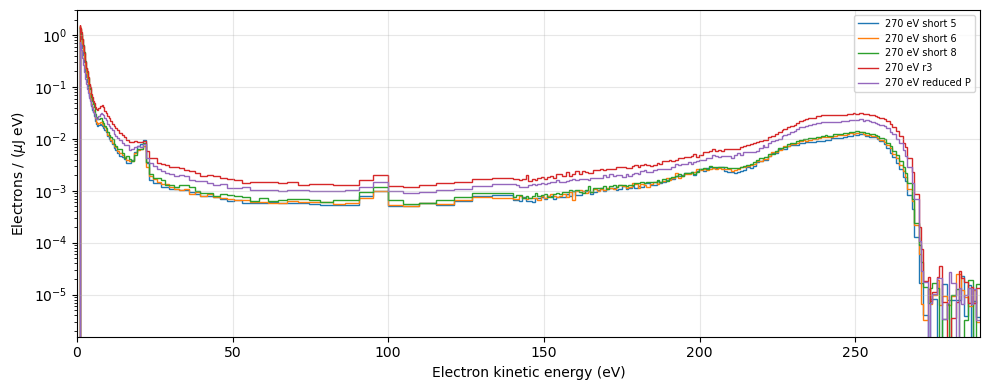

In [5]:
KE_LIM = (0, 290)

fig, ax = plt.subplots(figsize=(10, 4))
for name, s in spectra.items():
    ax.stairs(s['ref_e'], s['ke_edges'], label=name)
ax.set(xlabel='Electron kinetic energy (eV)', ylabel=f'Electrons / ({unit} eV)',
       xlim=KE_LIM, yscale='log')
ax.legend(fontsize = 7)
fig.tight_layout()
ax.grid(alpha=0.3)
plt.show()

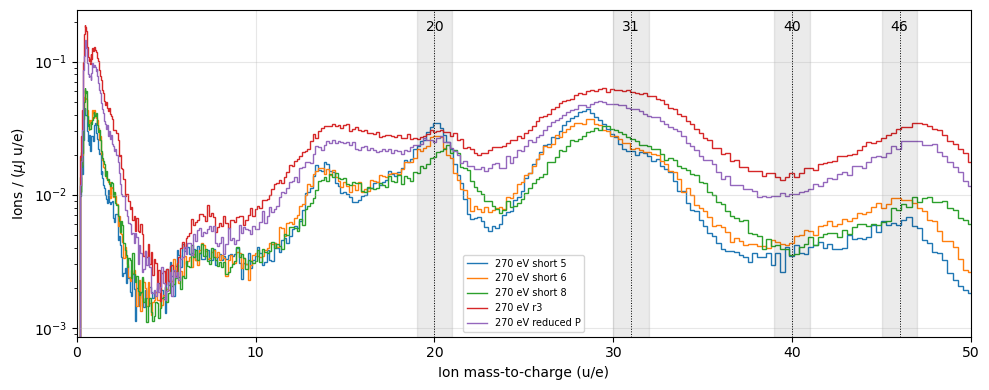

In [6]:
# Initial gates (u/e). Adjust after inspecting the zoomed spectra.
# These are deliberately not treated as resolved, species-pure ion peaks.
MASS_GATES = {
    20: (19, 21),     # Ar2+ candidate
    31: (30, 32),     # characteristic ethanol fragment candidate
    40: (39, 41),     # Ar+ candidate; may overlap molecular fragments
    46: (45, 47),     # ethanol parent candidate
}
MQ_LIM = (0, 50)

fig, ax = plt.subplots(figsize=(10, 4))
for name, s in spectra.items():
    ax.stairs(s['ref_i'], s['mq_edges'], label=name)
for mass, (lo, hi) in MASS_GATES.items():
    ax.axvspan(lo, hi, color='k', alpha=0.08)
    ax.axvline(mass, color='k', lw=0.7, ls=':')
    ax.text(mass, 0.97, str(mass), ha='center', va='top',
            transform=ax.get_xaxis_transform())
ax.set(xlabel='Ion mass-to-charge (u/e)', ylabel=f'Ions / ({unit} u/e)',
       xlim=MQ_LIM, yscale='log')
ax.legend(fontsize=7)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

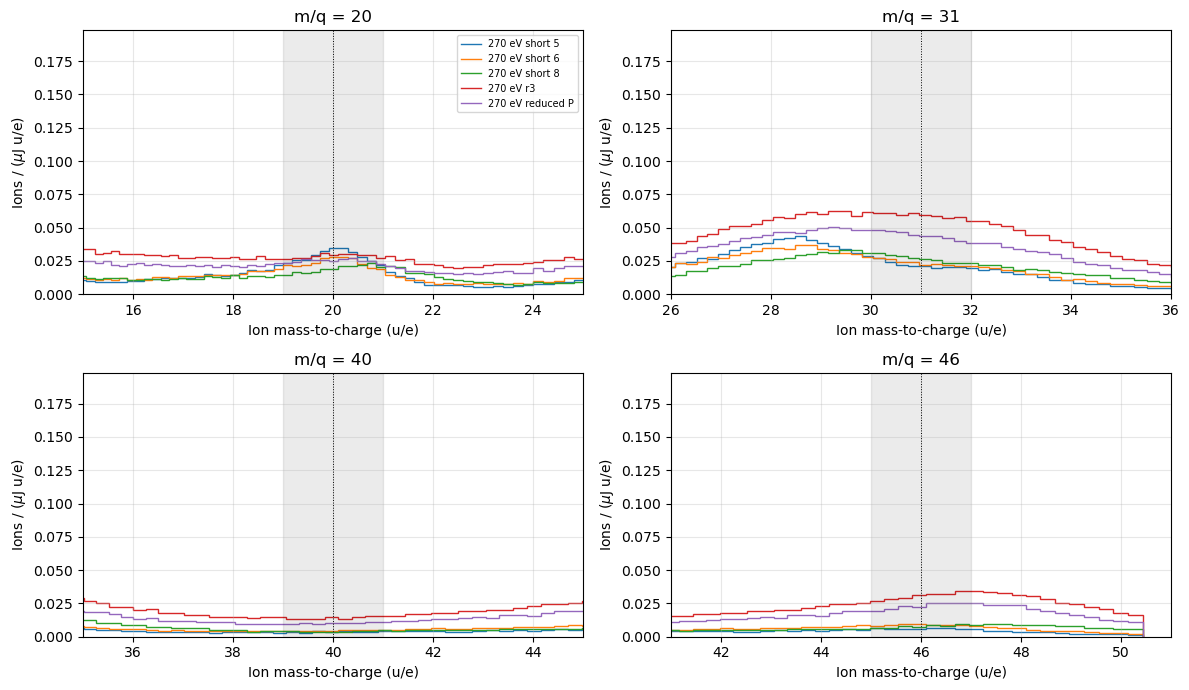

In [7]:
# Inspect the peak shape and possible calibration shifts around each gate.
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
for ax, (mass, (lo, hi)) in zip(axs.flat, MASS_GATES.items()):
    for name, s in spectra.items():
        ax.stairs(s['ref_i'], s['mq_edges'], label=name)
    ax.axvspan(lo, hi, color='k', alpha=0.08)
    ax.axvline(mass, color='k', lw=0.7, ls=':')
    ax.set(xlim=(lo - 4, hi + 4), ylim=(0, None),
           xlabel='Ion mass-to-charge (u/e)', ylabel=f'Ions / ({unit} u/e)',
           title=f'm/q = {mass}')
    ax.grid(alpha=0.3)
axs[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 3. Ion yields and argon-to-ethanol ratio

Integrate the ion density over the selected mass window, including fractional overlap with edge bins (assuming uniform density within each bin). No local background is subtracted: unresolved neighbouring ions or broad backgrounds may contribute. Mass 31 is motivated by the ethanol fragmentation paper in the beamtime log (Nixon et al., IJMS 404, 2016, 48–59), but its selectivity under the FEL conditions must be checked.

The ratio R = I20 / I31 is a contamination **proxy**, not an absolute concentration or a known argon fraction.

Ion yields (ions / uJ)
Group                              20           31           40           46      20 / 31
270 eV short 5               0.057014     0.044258    0.0072371     0.012324       1.2882
270 eV short 6               0.047301     0.047258    0.0093551     0.017754       1.0009
270 eV short 8               0.038209     0.053455    0.0079489     0.015589       0.7148
270 eV r3                    0.057717      0.11835      0.02839     0.061488       0.4877
270 eV reduced P             0.050462     0.089008     0.020403     0.046152       0.5669


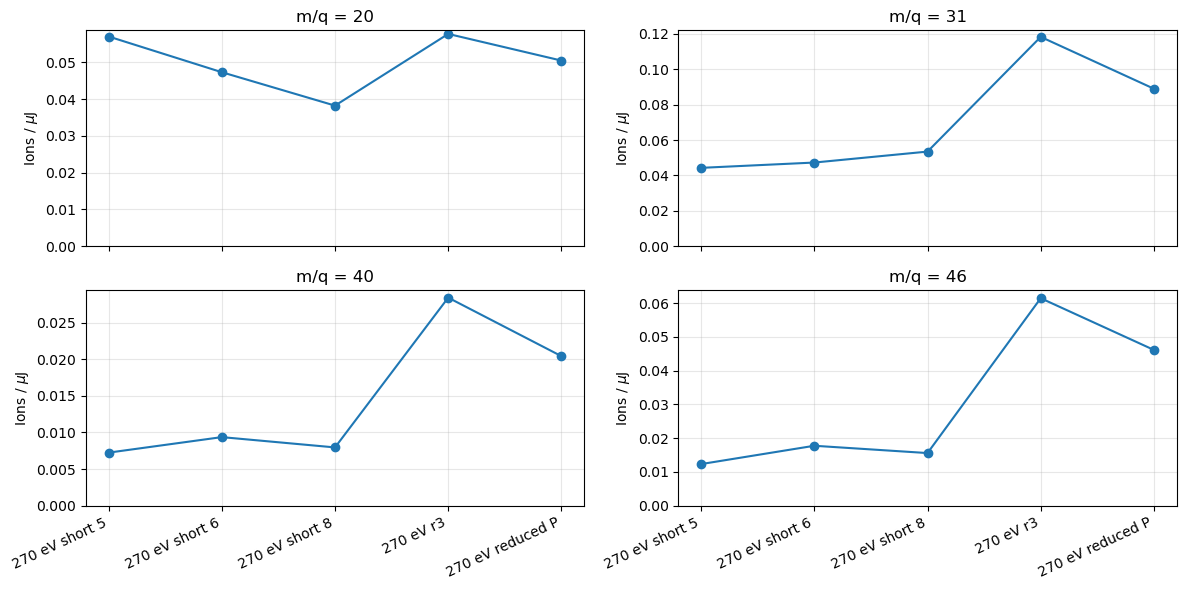

In [8]:
names = list(spectra)
masses = list(MASS_GATES)
x = np.arange(len(names))

# Integrate a density over a physical interval, accounting for bin widths.
def integrate_window(density, edges, lo, hi):
    if not edges[0] <= lo < hi <= edges[-1]:
        raise ValueError(f'Window {lo}–{hi} lies outside the calibrated axis')
    overlap = np.maximum(0, np.minimum(edges[1:], hi) - np.maximum(edges[:-1], lo))
    return np.sum(density * overlap)

ion_yields = {}
for name, s in spectra.items():
    ion_yields[name] = {
        mass: integrate_window(s['ref_i'], s['mq_edges'], lo, hi)
        for mass, (lo, hi) in MASS_GATES.items()
    }

I = {mass: np.array([ion_yields[name][mass] for name in names]) for mass in masses}
if np.any(~np.isfinite(I[31])) or np.any(I[31] <= 0):
    raise ValueError('Mass 31 yield must be finite and positive in every group')
R = I[20] / I[31]

print(f'Ion yields (ions / {NORMALISE.removeprefix("per_")})')
print(f'{"Group":24s}' + ''.join(f'{mass:>13d}' for mass in masses) + f'{"20 / 31":>13s}')
for j, name in enumerate(names):
    print(f'{name:24s}' + ''.join(f'{I[mass][j]:13.5g}' for mass in masses) + f'{R[j]:13.4f}')

fig, axs = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, mass in zip(axs.flat, masses):
    ax.plot(x, I[mass], 'o-')
    ax.set(ylabel=f'Ions / {unit}', title=f'm/q = {mass}', ylim=(0, None))
    ax.grid(alpha=0.3)
    ax.set_xticks(x, names, rotation=25, ha='right')
fig.tight_layout()
plt.show()

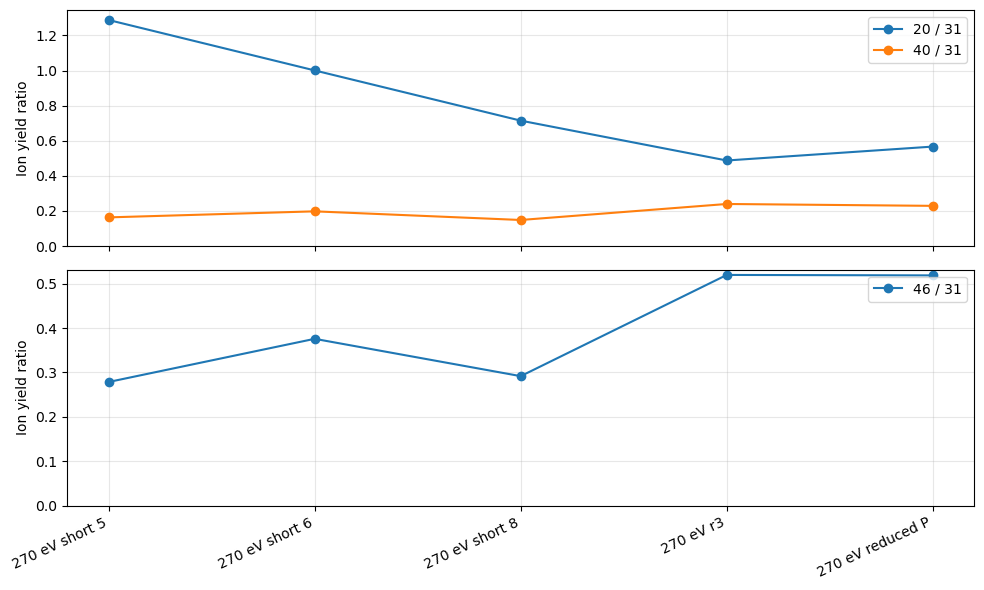

Ranked by 20 / 31 (lowest first):
  270 eV r3                0.4877
  270 eV reduced P         0.5669
  270 eV short 8           0.7148
  270 eV short 6           1.0009
  270 eV short 5           1.2882


In [9]:
# Ratios in acquisition order; the other markers are independent checks.
fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axs[0].plot(x, R, 'o-', label='20 / 31')
axs[0].plot(x, I[40] / I[31], 'o-', label='40 / 31')
axs[1].plot(x, I[46] / I[31], 'o-', label='46 / 31')
for ax in axs:
    ax.set(ylabel='Ion yield ratio', ylim=(0, None))
    ax.legend()
    ax.grid(alpha=0.3)
axs[-1].set_xticks(x, names, rotation=25, ha='right')
fig.tight_layout()
plt.show()

print('Ranked by 20 / 31 (lowest first):')
for j in np.argsort(R):
    print(f'  {names[j]:24s} {R[j]:.4f}')

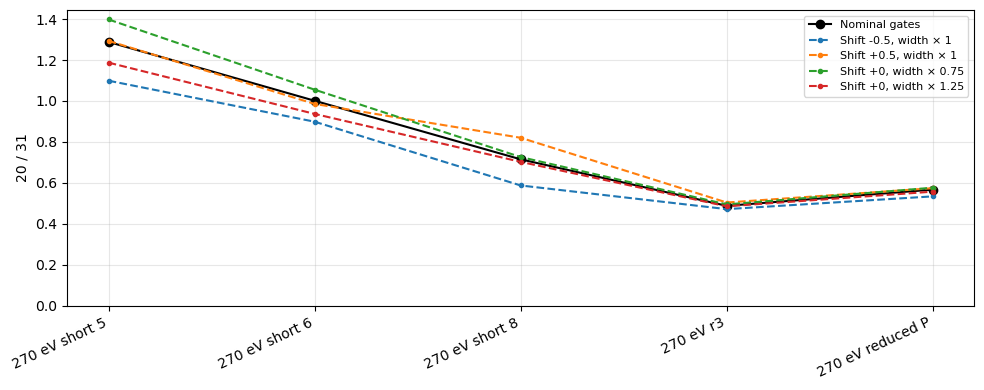

In [10]:
# Gate sensitivity: does the ordering change for nearby windows?
# These are diagnostic variations, not an optimisation of the gates.
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, R, 'o-', color='k', label='Nominal gates')
for shift, width in [(-0.5, 1), (0.5, 1), (0, 0.75), (0, 1.25)]:
    ratios = []
    for name, s in spectra.items():
        yields = {}
        for mass in (20, 31):
            lo, hi = MASS_GATES[mass]
            centre = (lo + hi) / 2 + shift
            half_width = (hi - lo) / 2 * width
            yields[mass] = integrate_window(s['ref_i'], s['mq_edges'],
                                            centre - half_width, centre + half_width)
        ratios.append(yields[20] / yields[31] if yields[31] > 0 else np.nan)
    ax.plot(x, ratios, '.--', label=f'Shift {shift:+g}, width × {width:g}')
ax.set(ylabel='20 / 31', ylim=(0, None))
ax.set_xticks(x, names, rotation=25, ha='right')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

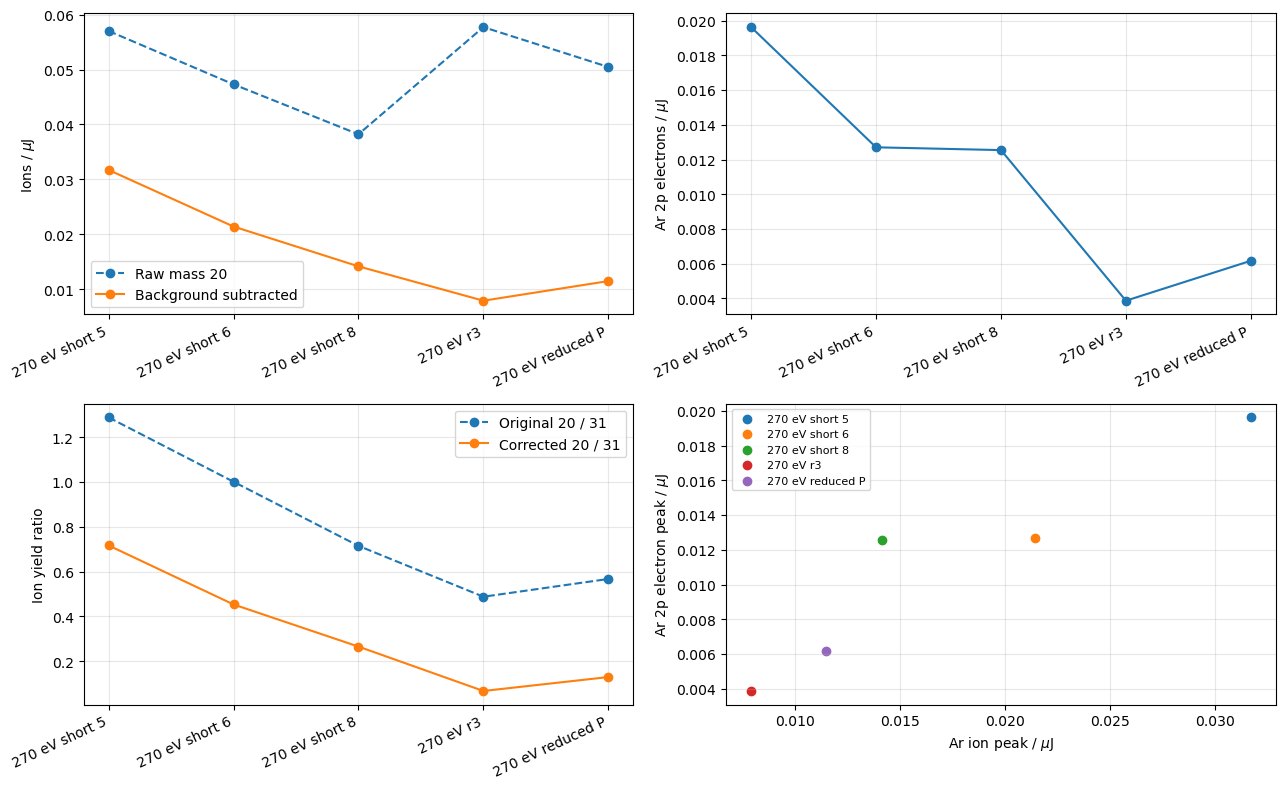

In [39]:
# Compare background-subtracted argon markers in ions and electrons.
# Initial windows -- inspect and adjust against the spectra.

AR_ION_GATE = (19, 21)
AR_ION_SIDEBANDS = ((17.5, 19), (22, 23.5))

AR_E_GATE = (18, 24)
AR_E_SIDEBANDS = ((14, 17), (25, 28))


def peak_yield(density, edges, gate, sidebands):
    lo, hi = gate
    left, right = sidebands

    # Mean density in each sideband
    y_left = integrate_window(density, edges, *left) / (left[1] - left[0])
    y_right = integrate_window(density, edges, *right) / (right[1] - right[0])

    # Linear local background
    x_left, x_right = np.mean(left), np.mean(right)
    background = y_left + (y_right - y_left) * (
        (np.mean(gate) - x_left) / (x_right - x_left)
    )

    raw = integrate_window(density, edges, lo, hi)

    return raw - background * (hi - lo)


Ar_i = np.array([
    peak_yield(spectra[name]['ref_i'],
               spectra[name]['mq_edges'],
               AR_ION_GATE, AR_ION_SIDEBANDS)
    for name in names
])

Ar_e = np.array([
    peak_yield(spectra[name]['ref_e'],
               spectra[name]['ke_edges'],
               AR_E_GATE, AR_E_SIDEBANDS)
    for name in names
])

R_i = Ar_i / I[31]
R_e = Ar_e / I[31]

fig, axs = plt.subplots(2, 2, figsize=(13, 8))

# Absolute argon markers
axs[0, 0].plot(x, I[20], 'o--', label='Raw mass 20')
axs[0, 0].plot(x, Ar_i, 'o-', label='Background subtracted')
axs[0, 0].set_ylabel(f'Ions / {unit}')
axs[0, 0].legend()

axs[0, 1].plot(x, Ar_e, 'o-')
axs[0, 1].set_ylabel(f'Ar 2p electrons / {unit}')

# Compare the original and new ratios
axs[1, 0].plot(x, R, 'o--', label='Original 20 / 31')
axs[1, 0].plot(x, R_i, 'o-', label='Corrected 20 / 31')
axs[1, 0].set_ylabel('Ion yield ratio')
axs[1, 0].legend()

# Compare independent argon markers
for j, name in enumerate(names):
    axs[1, 1].scatter(Ar_i[j], Ar_e[j], label=name)

axs[1, 1].set_xlabel(f'Ar ion peak / {unit}')
axs[1, 1].set_ylabel(f'Ar 2p electron peak / {unit}')
axs[1, 1].legend(fontsize=8)

for ax in (axs[0, 0], axs[0, 1], axs[1, 0]):
    ax.set_xticks(x, names, rotation=25, ha='right')

for ax in axs.flat:
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()


## 4. Electron spectra normalised to mass 31

Divide each electron density by the integrated ion yield in the mass 31 gate, using the same exposure and shots for both. The exposure cancels, leaving electrons per mass-31-gate ion per eV. This is not area normalisation. If the gate is a good ethanol marker and the detector response is stable, this should account for differences in ethanol density.

For subtraction and regression, require identical calibrated electron bins across groups. No interpolation or silent rebinning is used.

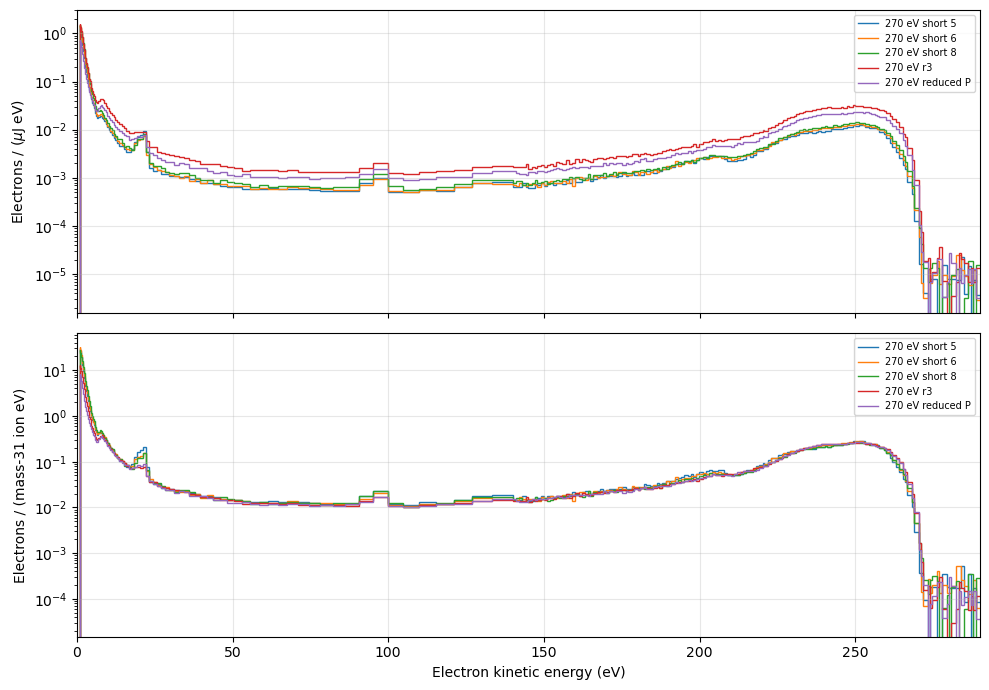

In [11]:
ke_edges = spectra[names[0]]['ke_edges']
for name in names:
    if not np.array_equal(spectra[name]['ke_edges'], ke_edges):
        raise ValueError(f'{name}: different electron energy edges; use common TOF bins before subtraction')
ke = (ke_edges[:-1] + ke_edges[1:]) / 2

S = np.stack([spectra[name]['ref_e'] / ion_yields[name][31] for name in names])
if not np.isfinite(S).all():
    raise ValueError('Non-finite electron spectra')

fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for j, name in enumerate(names):
    axs[0].stairs(spectra[name]['ref_e'], ke_edges, label=name)
    axs[1].stairs(S[j], ke_edges, label=name)
axs[0].set_ylabel(f'Electrons / ({unit} eV)')
axs[1].set_ylabel('Electrons / (mass-31 ion eV)')
axs[1].set_xlabel('Electron kinetic energy (eV)')
for ax in axs:
    ax.set(xlim=KE_LIM, yscale='log')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 5. Pairwise difference spectra

The default reference is the group with the lowest measured 20/31 ratio (not necessarily argon-free). Subtract its mass-31-normalised spectrum from each other group. If a fixed argon shape explains the differences, the difference spectra should have similar shapes after division by their respective differences in R.

Use a linear axis for signed differences. The highlighted KE windows are approximate argon markers at 270 eV, not exclusive argon gates. The normal Auger window is deliberately broad; the valence peaks overlap the ethanol spectrum.

Reference: 270 eV r3 (20/31 = 0.4877)
270 eV short 5           delta R = +0.80056
270 eV short 6           delta R = +0.51324
270 eV short 8           delta R = +0.22712
270 eV reduced P         delta R = +0.07926


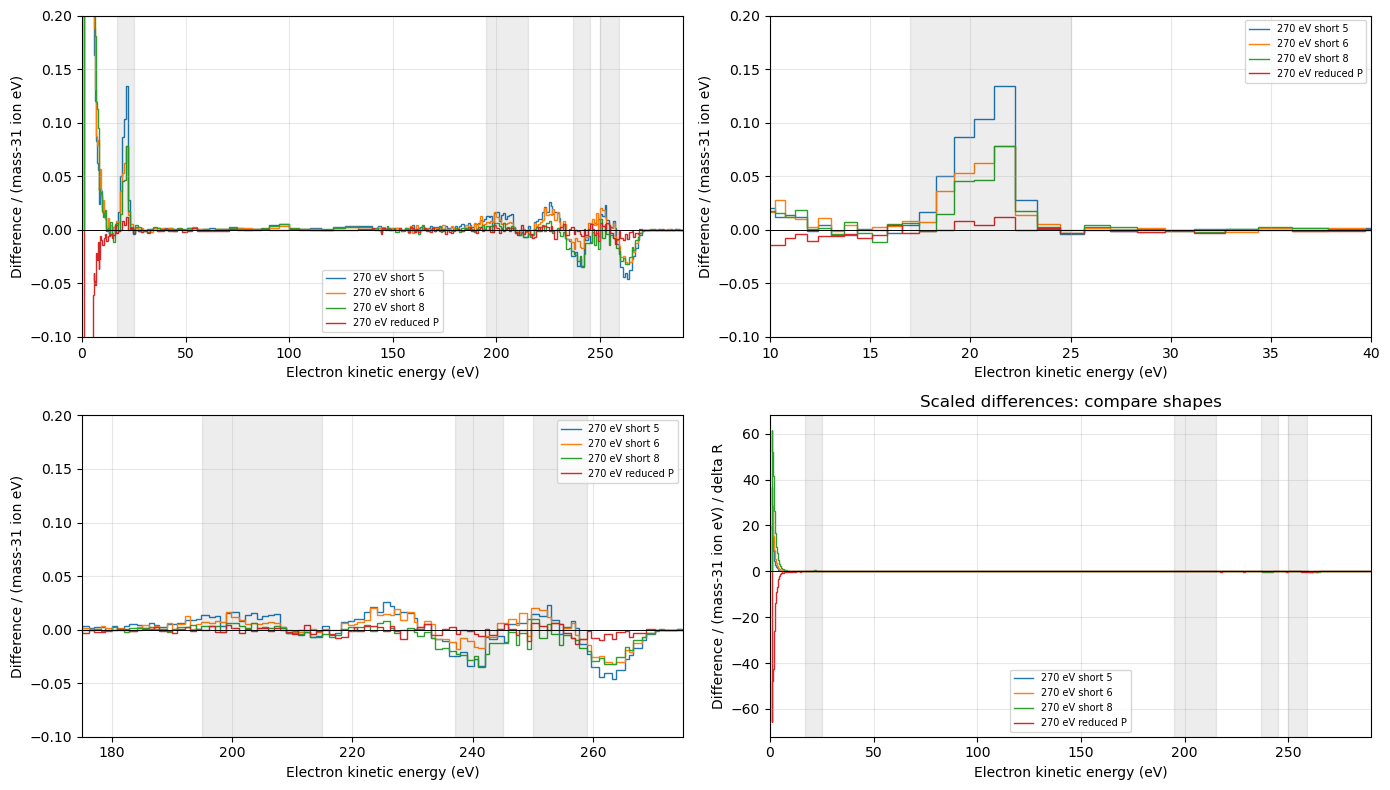

In [38]:
REFERENCE_GROUP = None   # None: lowest 20/31; or enter an exact name from GROUPS
AR_WINDOWS = {
    'Ar 2p': (17, 25),
    'Ar Auger': (195, 215),
    'Ar 3s': (237, 245),
    'Ar 3p': (250, 259),
}

j_ref = int(np.argmin(R)) if REFERENCE_GROUP is None else names.index(REFERENCE_GROUP)
print('Reference:', names[j_ref], f'(20/31 = {R[j_ref]:.4f})')

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
for j, name in enumerate(names):
    if j == j_ref:
        continue
    diff = S[j] - S[j_ref]
    axs[0, 0].stairs(diff, ke_edges, label=name)
    axs[0, 1].stairs(diff, ke_edges, label=name)
    axs[1, 0].stairs(diff, ke_edges, label=name)
    delta_R = R[j] - R[j_ref]
    print(f'{name:24s} delta R = {delta_R:+.5f}')
    if not np.isclose(delta_R, 0):
        axs[1, 1].stairs(diff / delta_R, ke_edges, label=name)
    else:
        print('  Equal ratios: skipping scaled difference')

for ax, lim in zip(axs.flat, (KE_LIM, (10, 40), (175, 275), KE_LIM)):
    ax.axhline(0, color='k', lw=0.7)
    for label, (lo, hi) in AR_WINDOWS.items():
        ax.axvspan(lo, hi, color='k', alpha=0.07)
    ax.set(xlim=lim, xlabel='Electron kinetic energy (eV)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
for ax in (axs[0, 0], axs[0, 1], axs[1, 0]):
    ax.set_ylabel('Difference / (mass-31 ion eV)')
    ax.set_ylim(-0.1,0.2)
    # ax.set_yscale('log')
axs[1, 1].set_ylabel('Difference / (mass-31 ion eV) / delta R')
axs[1, 1].set_title('Scaled differences: compare shapes')
fig.tight_layout()
plt.show()

## 6. Linear regression across runs

For each electron energy bin, fit the simple model

$$S_i(E) / I_{31,i} = F_{\mathrm{EtOH}}(E) + R_i F_{\mathrm{Ar}}(E),\qquad R_i = I_{20,i}/I_{31,i}.$$

The intercept estimates the ethanol spectrum per mass-31-gate ion at zero proxy ratio; the slope estimates an argon-associated spectrum per mass-20-gate ion. The corrected spectrum of each run in the original exposure units is its measured electron spectrum minus $I_{20,i}F_{\mathrm{Ar}}$.

This is an unweighted, exploratory fit across groups, not a shot-level fit. The ion ratios have uncertainty and share a denominator with the electron normalisation. Negative components are retained as diagnostics. The intercept can be biased by overlap in either ion gate, additional gas species, changes in collection efficiency, different GMD distributions or extrapolation. A two-group fit has no residual degrees of freedom; prefer three or more comparable groups.

Fit groups: 270 eV short 5, 270 eV short 6, 270 eV short 8, 270 eV r3, 270 eV reduced P
Fit R range: 0.4877 to 1.2882
Residual degrees of freedom: 3
Design matrix condition number: 5.73
Zero argon proxy is outside the measured range: intercept is an extrapolation.


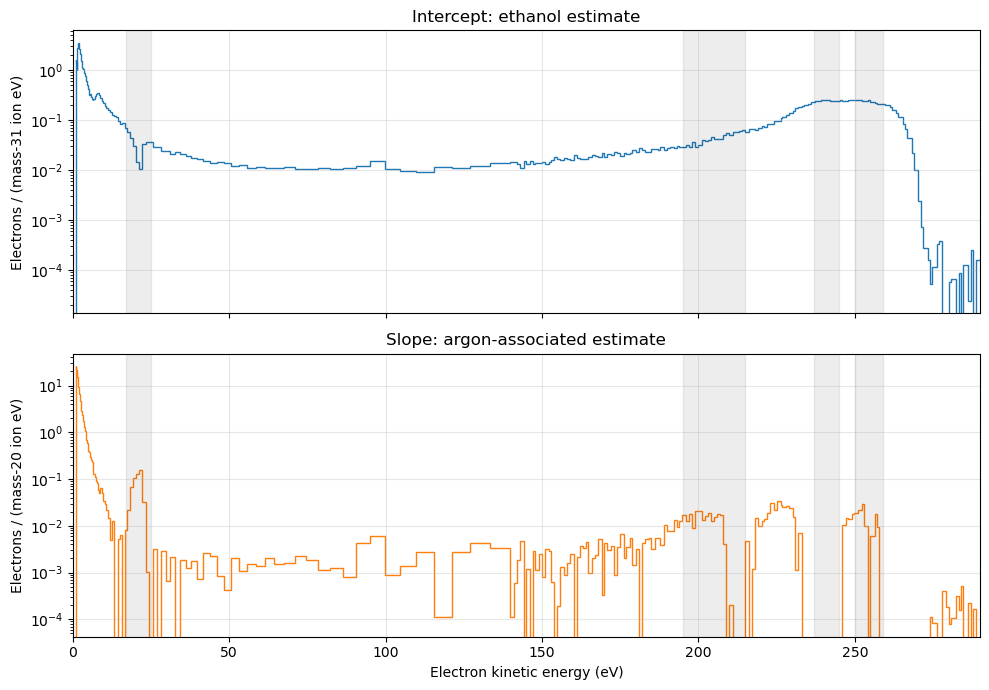

In [33]:
FIT_GROUPS = list(names)  # edit to exclude groups with different detector/gas settings
if len(set(FIT_GROUPS)) != len(FIT_GROUPS):
    raise ValueError('Duplicate fit groups')
fit_idx = np.array([names.index(name) for name in FIT_GROUPS], dtype=int)
if len(fit_idx) < 2:
    raise ValueError('Select at least two groups for the regression')

X = np.column_stack((np.ones(len(names)), R))
if np.linalg.matrix_rank(X[fit_idx]) < 2 or np.isclose(np.ptp(R[fit_idx]), 0):
    raise ValueError('Fit groups must have different argon-to-ethanol ratios')

F_EtOH, F_Ar = np.linalg.lstsq(X[fit_idx], S[fit_idx], rcond=None)[0]
S_fit = X @ np.stack((F_EtOH, F_Ar))
residual = S - S_fit

# In mass-31-normalised units and in the original exposure-normalised units.
S_corrected = S - R[:, None] * F_Ar
E_corrected = S_corrected * I[31][:, None]
E_argon = I[20][:, None] * F_Ar

print('Fit groups:', ', '.join(FIT_GROUPS))
print(f'Fit R range: {R[fit_idx].min():.4f} to {R[fit_idx].max():.4f}')
print(f'Residual degrees of freedom: {len(fit_idx) - 2}')
print(f'Design matrix condition number: {np.linalg.cond(X[fit_idx]):.2f}')
if R[fit_idx].min() > 0:
    print('Zero argon proxy is outside the measured range: intercept is an extrapolation.')

fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axs[0].stairs(F_EtOH, ke_edges, color='C0')
axs[0].set_ylabel('Electrons / (mass-31 ion eV)')
axs[0].set_title('Intercept: ethanol estimate')
axs[1].stairs(F_Ar, ke_edges, color='C1')
axs[1].set_ylabel('Electrons / (mass-20 ion eV)')
axs[1].set_title('Slope: argon-associated estimate')
axs[0].set_yscale('log')
axs[1].set_yscale('log')
for ax in axs:
    ax.axhline(0, color='k', lw=0.7)
    for label, (lo, hi) in AR_WINDOWS.items():
        ax.axvspan(lo, hi, color='k', alpha=0.07)
    ax.set(xlim=KE_LIM)
    ax.grid(alpha=0.3)
axs[-1].set_xlabel('Electron kinetic energy (eV)')
fig.tight_layout()
plt.show()

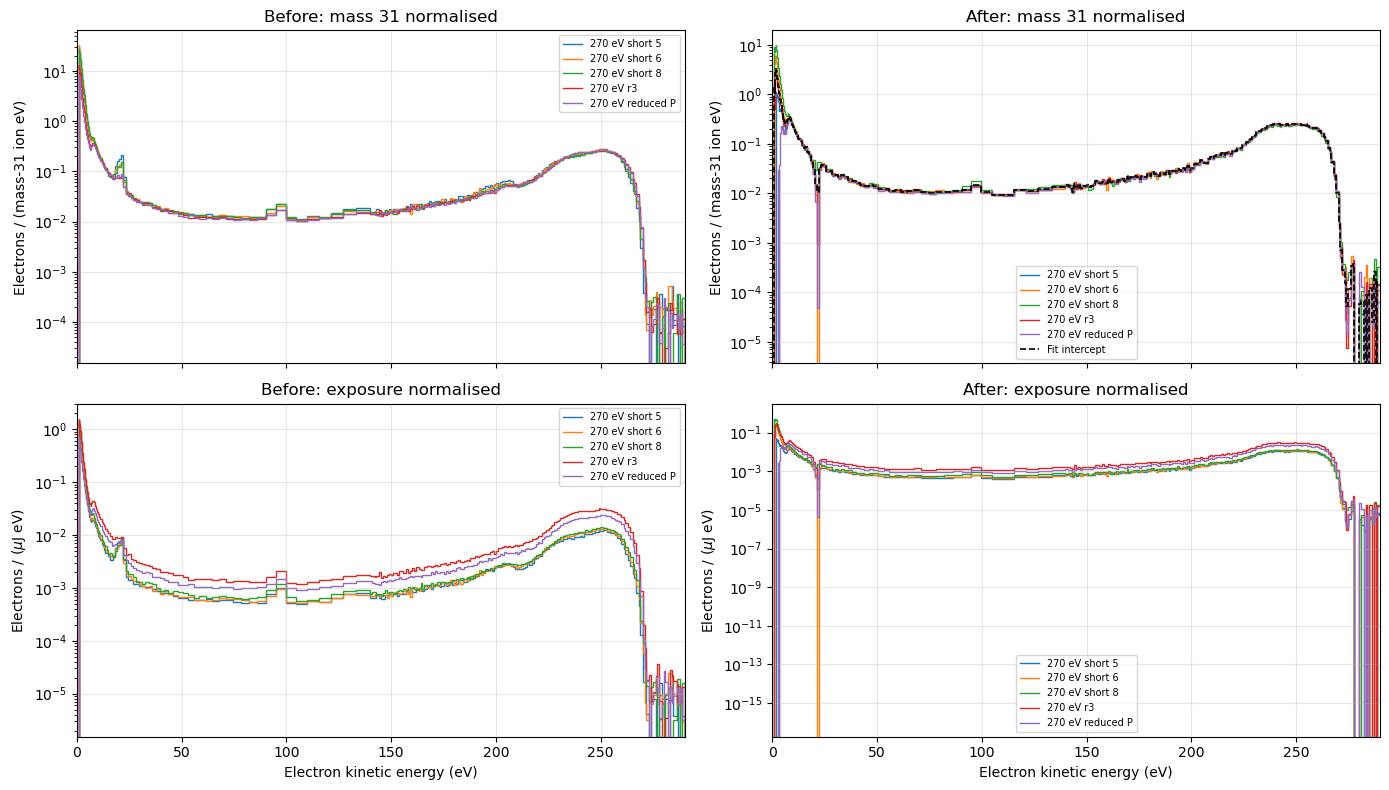

In [28]:
# Compare corrected spectra in both normalisations; keep negative values visible.
fig, axs = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for j, name in enumerate(names):
    axs[0, 0].stairs(S[j], ke_edges, label=name)
    axs[0, 1].stairs(S_corrected[j], ke_edges, label=name)
    axs[1, 0].stairs(spectra[name]['ref_e'], ke_edges, label=name)
    axs[1, 1].stairs(E_corrected[j], ke_edges, label=name)
axs[0, 1].stairs(F_EtOH, ke_edges, color='k', ls='--', lw=1.2, label='Fit intercept')
for ax, title in zip(axs.flat, ('Before: mass 31 normalised', 'After: mass 31 normalised',
                               'Before: exposure normalised', 'After: exposure normalised')):
    ax.set(title=title, xlim=KE_LIM)
    ax.axhline(0, color='k', lw=0.7)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
for ax in axs[0]:
    ax.set_ylabel('Electrons / (mass-31 ion eV)')
    ax.set_yscale('log')
for ax in axs[1]:
    ax.set(xlabel='Electron kinetic energy (eV)', ylabel=f'Electrons / ({unit} eV)', yscale = 'log')
fig.tight_layout()
plt.show()

## 7. Model checks

A closer match after subtracting a slope fitted from these same spectra is not independent validation. Inspect the residual spectra and the trends in the physical argon windows. Repeat the analysis with changed gates, similar GMD distributions and fit subsets before interpreting the components.

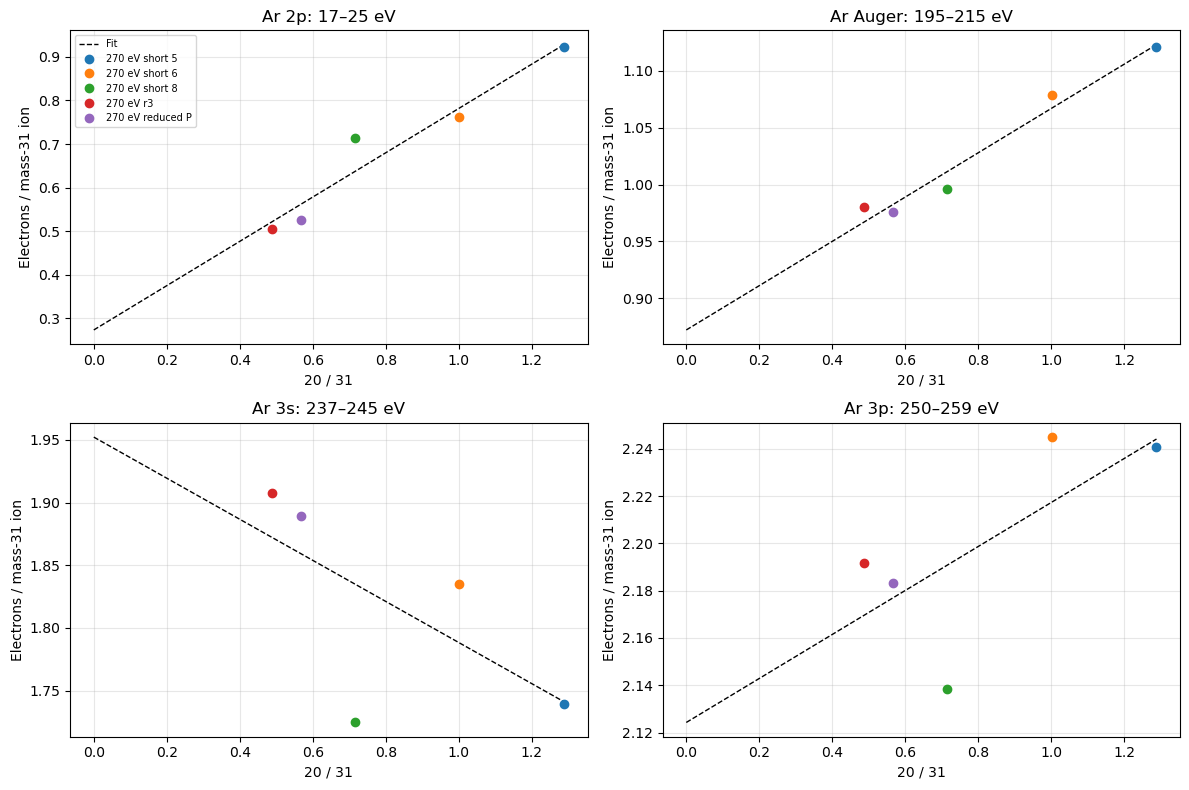

In [29]:
# Check the dependence on R in selected KE windows (integrated counts, not density sums).
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
R_line = np.linspace(0, R.max(), 100)
for ax, (label, (lo, hi)) in zip(axs.flat, AR_WINDOWS.items()):
    y = np.array([integrate_window(s, ke_edges, lo, hi) for s in S])
    a = integrate_window(F_EtOH, ke_edges, lo, hi)
    b = integrate_window(F_Ar, ke_edges, lo, hi)
    ax.plot(R_line, a + b * R_line, 'k--', lw=1, label='Fit')
    for j, name in enumerate(names):
        ax.plot(R[j], y[j], 'o' if j in fit_idx else 'x', label=name)
    ax.set(xlabel='20 / 31', ylabel='Electrons / mass-31 ion',
           title=f'{label}: {lo}–{hi} eV')
    ax.grid(alpha=0.3)
axs[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

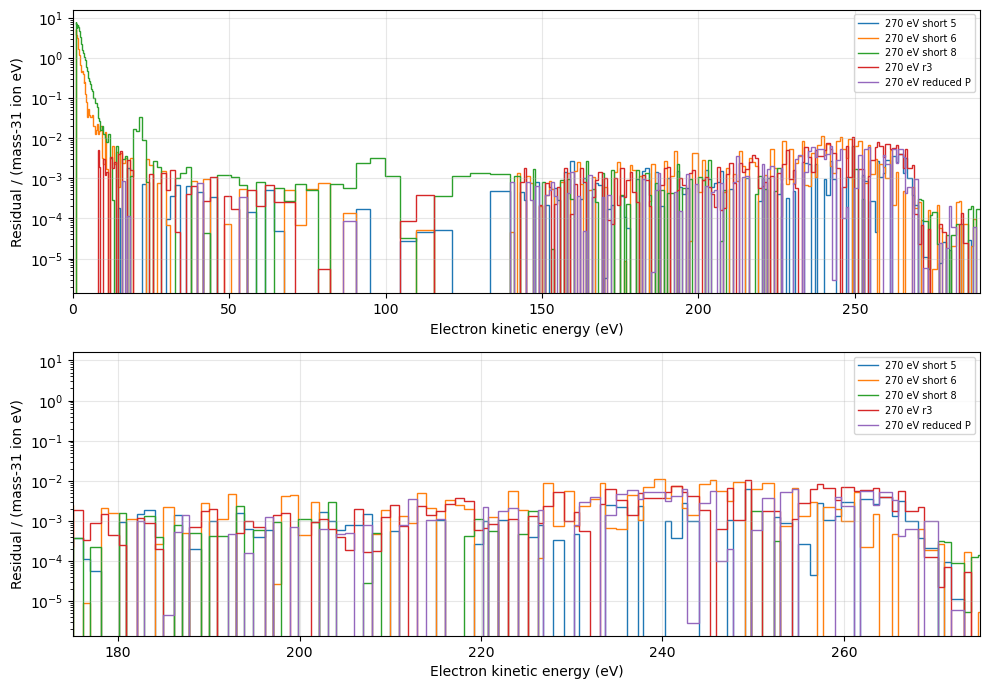

270 eV short 5           relative absolute residual: 11.20%
270 eV short 6           relative absolute residual: 9.07%
270 eV short 8           relative absolute residual: 25.14%
270 eV r3                relative absolute residual: 5.84%
270 eV reduced P         relative absolute residual: 38.54%


In [31]:
# Residual spectra: look for structured features not explained by the two-component model.
fig, axs = plt.subplots(2, 1, figsize=(10, 7))
for j, name in enumerate(names):
    label = name if j in fit_idx else name + ' (not fitted)'
    for ax in axs:
        ax.stairs(residual[j], ke_edges, label=label)
for ax, lim in zip(axs, (KE_LIM, (175, 275))):
    ax.axhline(0, color='k', lw=0.7)
    ax.set(xlim=lim, xlabel='Electron kinetic energy (eV)',
           ylabel='Residual / (mass-31 ion eV)', yscale = 'log')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

# Width-weighted absolute residual relative to measured yield (full calibrated axis).
for j, name in enumerate(names):
    err = np.sum(np.abs(residual[j]) * np.diff(ke_edges))
    total = np.sum(S[j] * np.diff(ke_edges))
    print(f'{name:24s} relative absolute residual: {err / total:.2%}' if total > 0 else name + ': no electron yield')

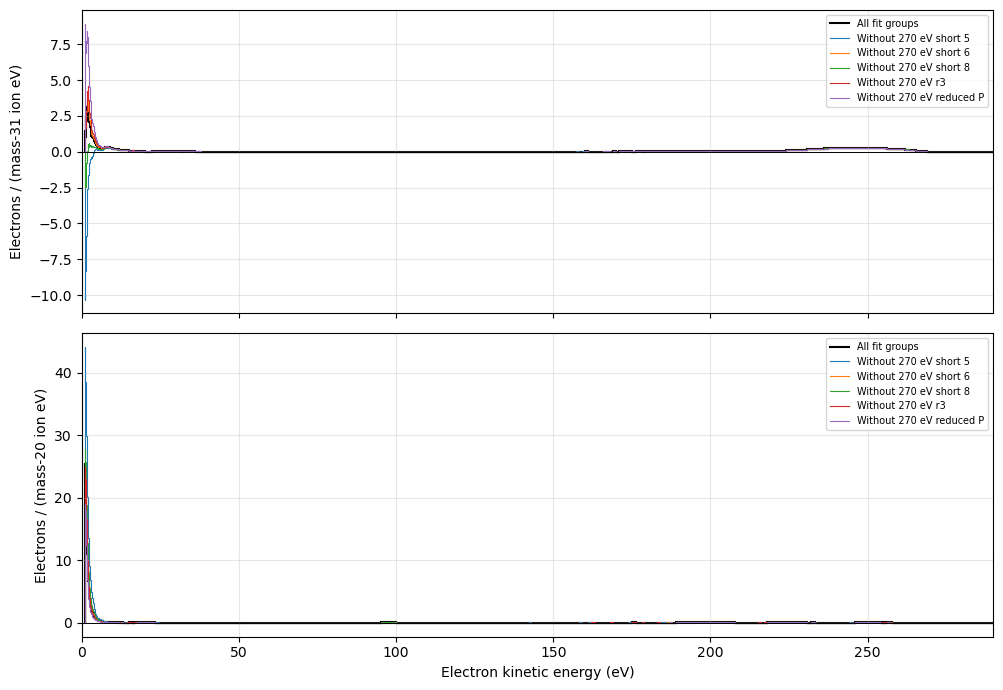

In [17]:
# Leave one fit group out: check how sensitive the reconstructed components are.
# This is a stability diagnostic, not a statistical confidence interval.
if len(fit_idx) < 3:
    print('Need at least three fit groups for leave-one-out fits.')
else:
    fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    axs[0].stairs(F_EtOH, ke_edges, color='k', lw=1.5, label='All fit groups')
    axs[1].stairs(F_Ar, ke_edges, color='k', lw=1.5, label='All fit groups')
    for j in fit_idx:
        keep = fit_idx[fit_idx != j]
        if np.linalg.matrix_rank(X[keep]) < 2 or np.isclose(np.ptp(R[keep]), 0):
            print(f'Skipping {names[j]}: remaining ratios are too similar')
            continue
        a, b = np.linalg.lstsq(X[keep], S[keep], rcond=None)[0]
        label = 'Without ' + names[j]
        axs[0].stairs(a, ke_edges, lw=0.8, label=label)
        axs[1].stairs(b, ke_edges, lw=0.8, label=label)
    axs[0].set_ylabel('Electrons / (mass-31 ion eV)')
    axs[1].set_ylabel('Electrons / (mass-20 ion eV)')
    for ax in axs:
        ax.axhline(0, color='k', lw=0.7)
        ax.set(xlim=KE_LIM)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    axs[-1].set_xlabel('Electron kinetic energy (eV)')
    fig.tight_layout()
    plt.show()

## Comparing approaches


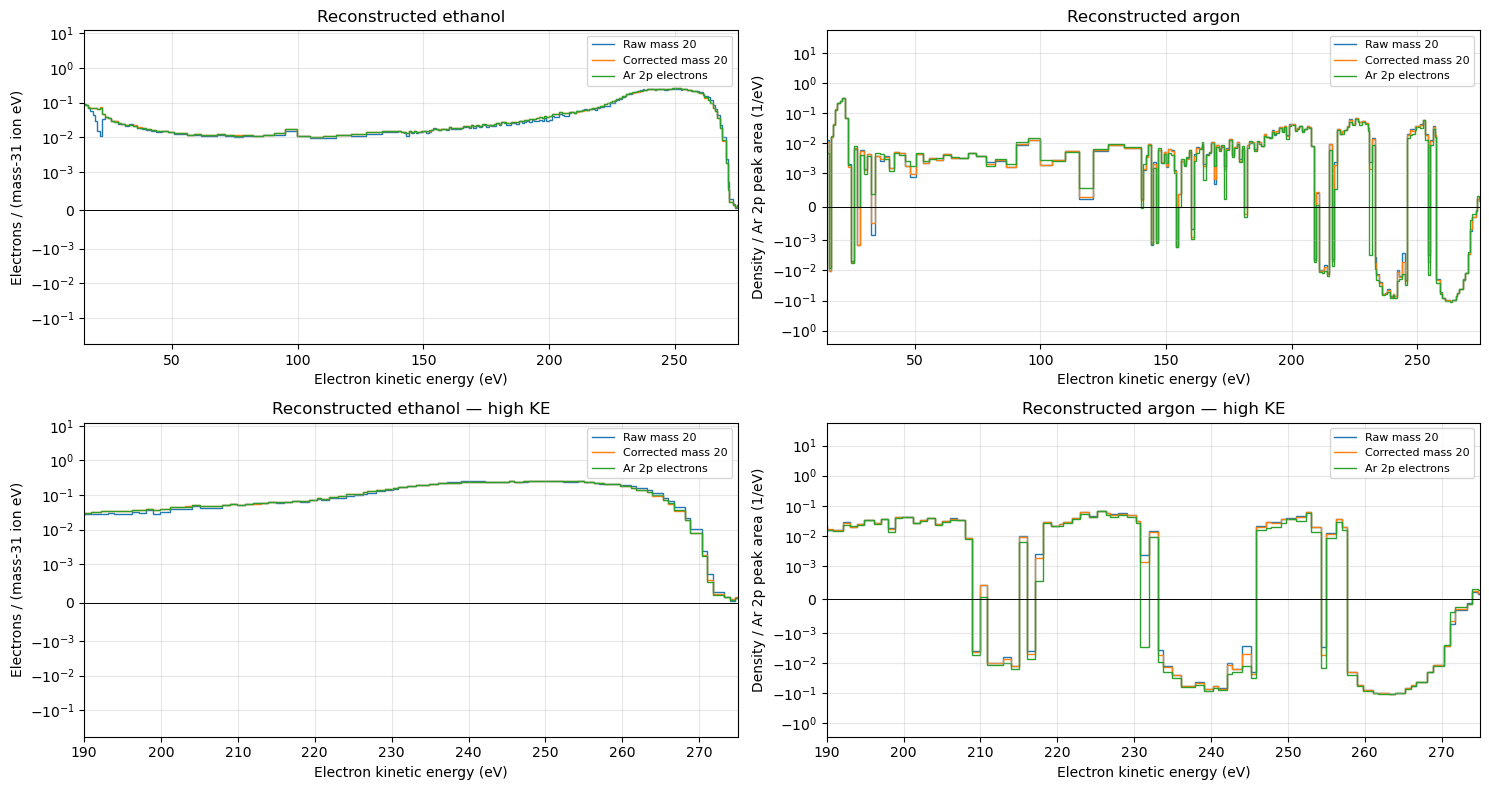

In [42]:
# Compare the reconstructed components using different argon markers.

AR_MARKERS = {
    'Raw mass 20': R,
    'Corrected mass 20': R_i,
    'Ar 2p electrons': R_e,
}

FIT_GROUPS_TEST = list(names)
# FIT_GROUPS_TEST.remove('270 eV short 8')

idx = np.array([names.index(name) for name in FIT_GROUPS_TEST])

components = {}

fig, axs = plt.subplots(2, 2, figsize=(15, 8))

for label, ratio in AR_MARKERS.items():

    X_test = np.column_stack((np.ones(len(names)), ratio))

    if np.linalg.matrix_rank(X_test[idx]) < 2:
        raise ValueError(f'Cannot separate components using {label}')

    a, b = np.linalg.lstsq(X_test[idx], S[idx], rcond=None)[0]

    corrected = S - ratio[:, None] * b

    components[label] = {
        'ethanol': a,
        'argon': b,
        'corrected': corrected,
        'residual': S - X_test @ np.stack((a, b)),
    }

    # Normalise the reconstructed Ar spectra to their 2p peak
    # so that we can compare their shapes despite different units.
    ar_peak = peak_yield(
        b, ke_edges, AR_E_GATE, AR_E_SIDEBANDS
    )

    if ar_peak > 0:
        axs[0, 1].stairs(b / ar_peak, ke_edges, label=label)
        axs[1, 1].stairs(b / ar_peak, ke_edges, label=label)
    else:
        print(f'{label}: non-positive Ar 2p peak')

    axs[0, 0].stairs(a, ke_edges, label=label)
    axs[1, 0].stairs(a, ke_edges, label=label)

axs[0, 0].set_title('Reconstructed ethanol')
axs[0, 1].set_title('Reconstructed argon')
axs[1, 0].set_title('Reconstructed ethanol — high KE')
axs[1, 1].set_title('Reconstructed argon — high KE')

for ax in axs[0]:
    ax.set_xlim(15, 275)

for ax in axs[1]:
    ax.set_xlim(190, 275)

for ax in axs[:, 0]:
    ax.set_ylabel('Electrons / (mass-31 ion eV)')

for ax in axs[:, 1]:
    ax.set_ylabel('Density / Ar 2p peak area (1/eV)')

for ax in axs.flat:
    ax.axhline(0, color='k', lw=0.7)
    ax.set_yscale('symlog', linthresh=1e-3)
    ax.set_xlabel('Electron kinetic energy (eV)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

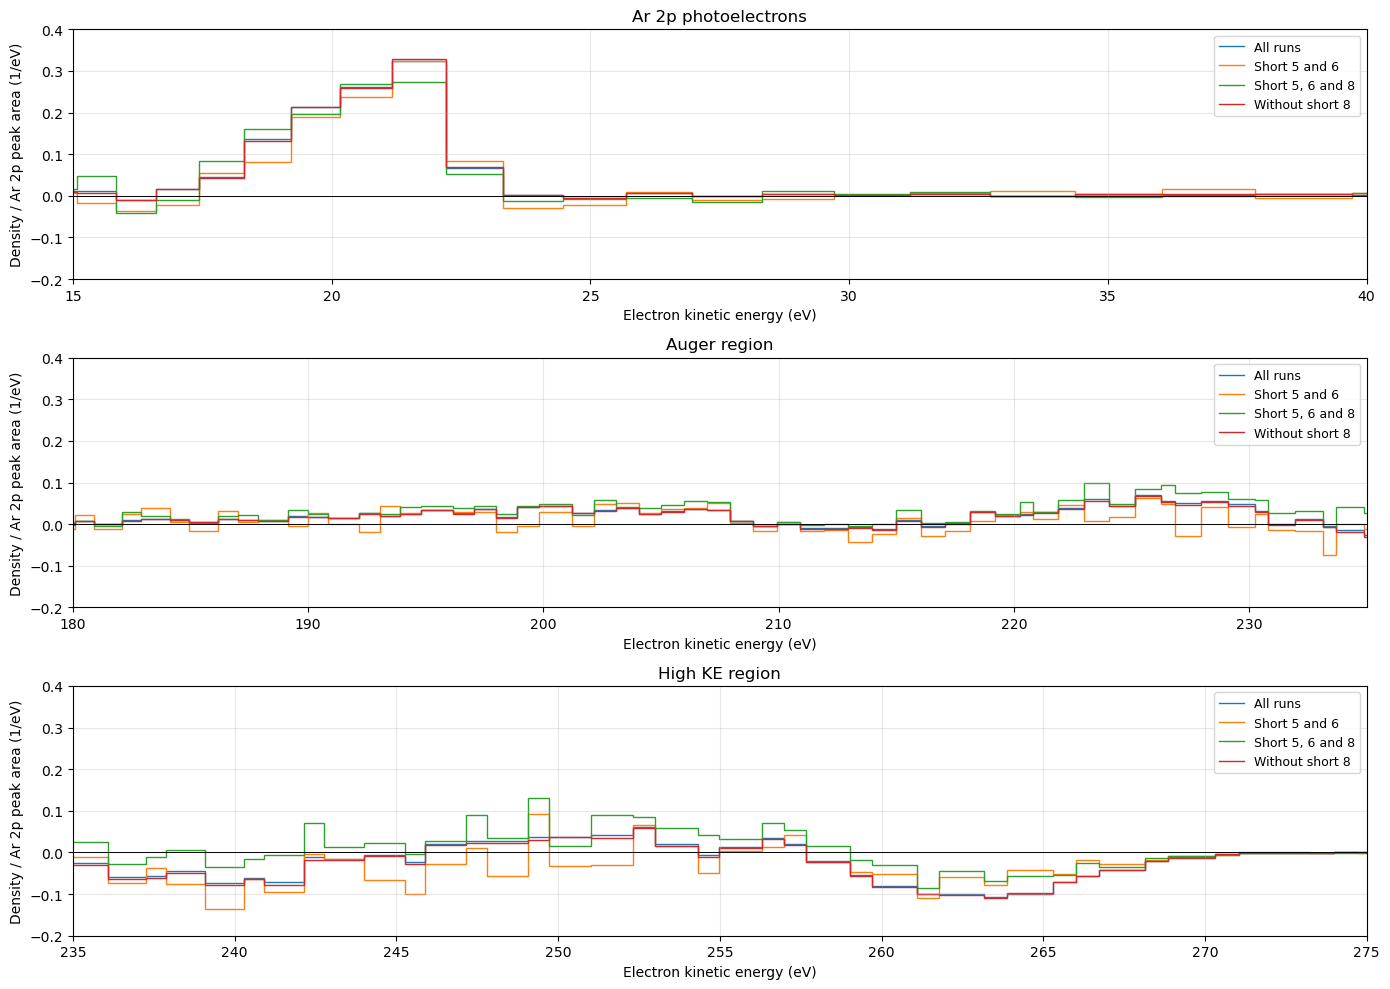

In [49]:
# Sensitivity of the reconstructed argon spectrum to run selection

RUN_SELECTIONS = {
    'All runs': list(names),

    'Short 5 and 6': [
        '270 eV short 5',
        '270 eV short 6',
    ],

    'Short 5, 6 and 8': [
        '270 eV short 5',
        '270 eV short 6',
        '270 eV short 8',
    ],

    'Without short 8': [
        name for name in names
        if name != '270 eV short 8'
    ],
}

ratio = R_i

fig, axs = plt.subplots(3, 1, figsize=(14, 10))

for label, groups in RUN_SELECTIONS.items():

    idx = np.array([names.index(name) for name in groups])

    X_test = np.column_stack((
        np.ones(len(idx)),
        ratio[idx]
    ))

    if np.linalg.matrix_rank(X_test) < 2:
        print(f'{label}: insufficient variation in argon marker')
        continue

    a, b = np.linalg.lstsq(X_test, S[idx], rcond=None)[0]

    # Normalise to the reconstructed Ar 2p peak area
    ar_peak = peak_yield(
        b, ke_edges, AR_E_GATE, AR_E_SIDEBANDS
    )

    if ar_peak <= 0:
        print(f'{label}: non-positive Ar 2p peak')
        continue

    for ax in axs:
        ax.stairs(b / ar_peak, ke_edges, label=label)

axs[0].set_xlim(15, 40)
axs[1].set_xlim(180, 235)
axs[2].set_xlim(235, 275)

axs[0].set_title('Ar 2p photoelectrons')
axs[1].set_title('Auger region')
axs[2].set_title('High KE region')

for ax in axs:
    ax.axhline(0, color='k', lw=0.7)
    ax.set_xlabel('Electron kinetic energy (eV)')
    ax.set_ylabel('Density / Ar 2p peak area (1/eV)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    ax.set_ylim(-0.2,0.4)

fig.tight_layout()
plt.show()

Mass 31         | scale = 1.0000 | change = +0.00%
40–80 eV        | scale = 1.0180 | change = +1.80%
80–120 eV       | scale = 1.0570 | change = +5.70%
120–160 eV      | scale = 1.0689 | change = +6.89%
40–160 eV       | scale = 1.0487 | change = +4.87%


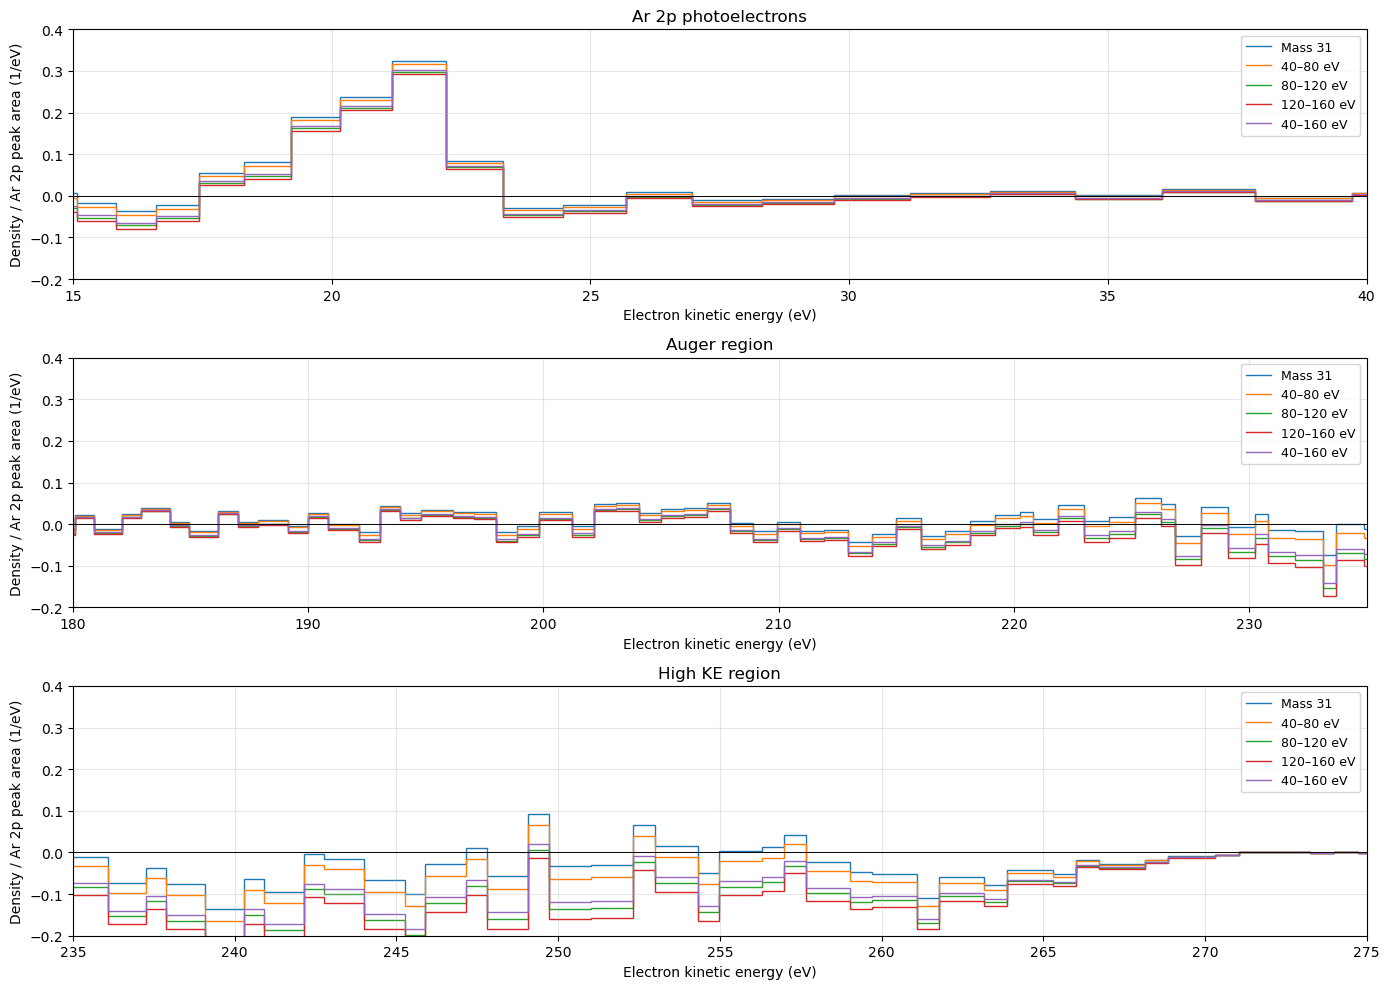

In [52]:
# Test alternative ethanol normalisations using short 5 and short 6.

HIGH_AR = '270 eV short 5'
LOW_AR = '270 eV short 6'

NORM_WINDOWS = [
    (40, 80),
    (80, 120),
    (120, 160),
    (40, 160),
]

i = names.index(HIGH_AR)
j = names.index(LOW_AR)

# Spectra already normalised to mass 31
s_high = S[i]
s_low = S[j]

scales = {'Mass 31': 1.0}

for lo, hi in NORM_WINDOWS:

    y_high = integrate_window(s_high, ke_edges, lo, hi)
    y_low = integrate_window(s_low, ke_edges, lo, hi)

    scales[f'{lo}–{hi} eV'] = y_high / y_low


fig, axs = plt.subplots(3, 1, figsize=(14, 10))

for label, scale in scales.items():

    difference = s_high - scale * s_low

    ar_peak = peak_yield(
        difference, ke_edges,
        AR_E_GATE, AR_E_SIDEBANDS
    )

    print(f'{label:15s} | scale = {scale:.4f} '
          f'| change = {(scale - 1) * 100:+.2f}%')

    if ar_peak <= 0:
        print('Non-positive Ar 2p peak')
        continue

    for ax in axs:
        ax.stairs(difference / ar_peak, ke_edges, label=label)

axs[0].set_xlim(15, 40)
axs[1].set_xlim(180, 235)
axs[2].set_xlim(235, 275)

axs[0].set_title('Ar 2p photoelectrons')
axs[1].set_title('Auger region')
axs[2].set_title('High KE region')

for ax in axs:
    ax.axhline(0, color='k', lw=0.7)
    ax.set_xlabel('Electron kinetic energy (eV)')
    ax.set_ylabel('Density / Ar 2p peak area (1/eV)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    ax.set_ylim(-0.2,0.4)

fig.tight_layout()
plt.show()

### Before using this correction for delay traces

- Verify that the 20 and 31 gates track argon and ethanol, respectively. In particular, the 31 gate may contain nearby molecular fragments or broad background, and the 20 gate may contain non-argon ions. The 40 and 46 gates are cross-checks, not assumed pure.
- Check the relative ion ratios and reconstructed spectra for different gate widths/positions, comparable GMD distributions and groups before/after needle motion. Rerun with a common delay interval (default) and with the original scan coverage as a sensitivity check. GMD indices may correspond to different physical pulse energies in different files; inspect the printed edges.
- Compare the reconstructed argon shape with the separate argon reference at 4.4 nm (~281.8 eV): photoelectron features shift by ~11.8 eV between the two photon energies, normal Auger features approximately do not. Do not subtract that reference directly.
- Inspect the argon proxy versus delay and laboratory time before any time-dependent correction. A changing gas concentration can mimic delay dependence during a continuous scan.
- Subtracting an estimated background does not remove the counting noise from argon. First moments suffice for these exploratory spectra, but reliable uncertainties require additional statistics (e.g. independent acquisition blocks and propagation of the shared ion-marker uncertainty). The present notebook does not estimate confidence intervals or apply a correction to time-resolved data.